# Strategy 1 - Finding B using regression

In [499]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
from scipy.stats import chi2
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox





In [319]:
# Reading the data 
df = pd.read_csv("Data/price_data.csv", header = 3)
df["Date"] = pd.to_datetime(df['Date'])
df.set_index("Date", inplace=True)
df.head()

/var/folders/nb/jqk45f293z3bx3hy7zrjcv0c0000gn/T/ipykernel_13191/3791631968.py:2: DtypeWarning: Columns (5,64,138,248,268,280,322,355,367,396,447,450,472,509) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("Data/price_data.csv", header = 3)


,Line#,LYB UN,AXP UN,VZ UN,TPL UN,AVGO UW,BA UN,SOLV UN,CAT UN,JPM UN,...,ZTS UN,ARES UN,COIN UW,EQIX UW,DLR UN,MOH UN,LVS UN,Unnamed: 546,Unnamed: 547,Unnamed: 548
Date,,,,,,,,,,,,,,,,,,,,,
2010-07-30,6,NaN,36.08,13.66,7.62,1.56,53.77,NaN,47.87,27.04,...,NaN,NaN,NaN,70.34,34.63,19.87,17.26,NaN,NaN,NaN
2010-08-02,9,NaN,36.36,13.90,7.91,1.57,54.99,NaN,48.76,27.95,...,NaN,NaN,NaN,70.71,35.02,20.33,17.96,NaN,NaN,NaN
2010-08-03,10,NaN,36.05,13.89,7.93,1.55,54.87,NaN,48.30,27.57,...,NaN,NaN,NaN,70.74,34.43,20.69,18.07,NaN,NaN,NaN
2010-08-04,11,NaN,35.65,13.82,8.06,1.60,54.98,NaN,48.81,27.72,...,NaN,NaN,NaN,70.88,34.06,21.14,18.56,NaN,NaN,NaN
2010-08-05,12,NaN,34.93,13.89,8.06,1.63,54.55,NaN,49.39,27.70,...,NaN,NaN,NaN,70.71,33.23,18.87,18.35,NaN,NaN,NaN


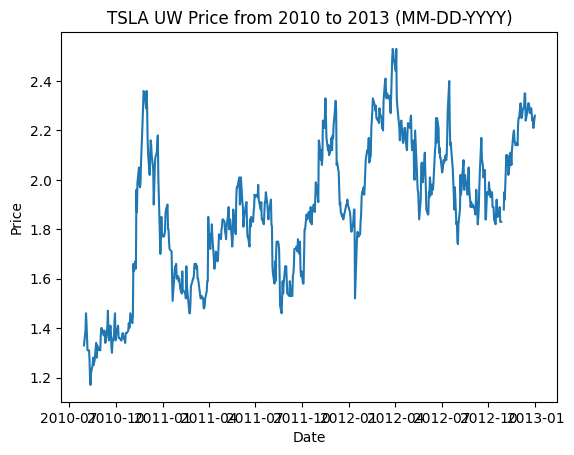

Date
2010-08-03    0.049133
2010-08-04   -0.027780
2010-08-05   -0.043172
2010-08-06   -0.037458
2010-08-09    0.000000
                ...   
2012-12-24    0.008772
2012-12-26   -0.022076
2012-12-27    0.004454
2012-12-28   -0.017938
2012-12-31    0.022372
Name: TSLA UW, Length: 607, dtype: float64


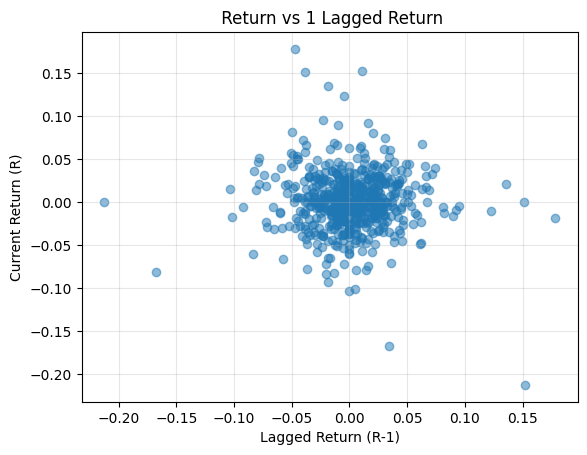

                               SARIMAX Results                                
Dep. Variable:                TSLA UW   No. Observations:                  607
Model:                 ARIMA(1, 0, 1)   Log Likelihood                1186.354
Date:                Mon, 29 Sep 2025   AIC                          -2364.709
Time:                        21:52:51   BIC                          -2347.074
Sample:                             0   HQIC                         -2357.848
                                - 607                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0008      0.001      0.716      0.474      -0.001       0.003
ar.L1          0.7005      0.177      3.951      0.000       0.353       1.048
ma.L1         -0.7717      0.161     -4.797      0.0

/Users/nmjos/Documents/University/COMPSCI 399 Capstone/.venv/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/Users/nmjos/Documents/University/COMPSCI 399 Capstone/.venv/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/Users/nmjos/Documents/University/COMPSCI 399 Capstone/.venv/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/Users/nmjos/Documents/University/COMPSCI 399 Capstone/.venv/lib/python3.10/site-packages/statsmodel

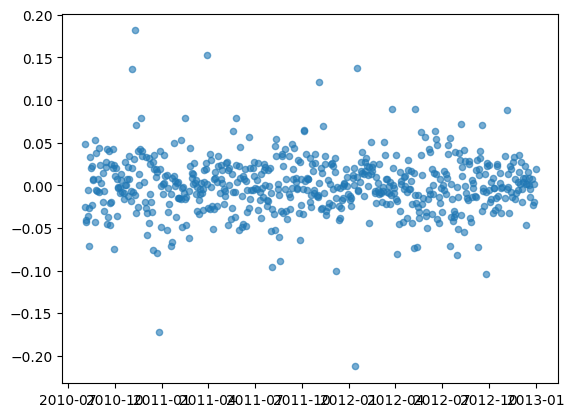

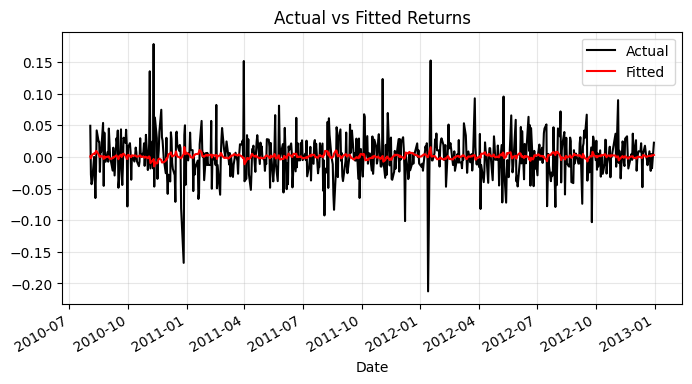

In [501]:
def plot_stock_price(stock, start_date, end_date):
    plt.plot(stock.index, stock.values, label="Stock Price")
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.title(f"{stock.name} Price from {start_date} to {end_date} (MM-DD-YYYY)")
    plt.show()

def get_stock_data(stock_symbol, start_date, end_date):
    stock = df[stock_symbol]
    stock = stock.loc[pd.to_datetime(start_date):pd.to_datetime(end_date)]
    return stock


def plot_return_lagged_return(returns, returns_lagged, lag):
    
    plt.scatter(returns, returns_lagged, alpha=0.5)
    plt.xlabel(f"Lagged Return (R-{lag})")
    plt.ylabel("Current Return (R)")
    plt.title(f" Return vs {lag} Lagged Return")
    plt.grid(True, alpha=0.3)
    plt.show()

def plot_acf_pacf(series, lags=40):
 
    plt.subplot(1,2,1)
    plot_acf(series, lags=lags, ax=plt.gca())
    plt.title(f"ACF of {series.name}")
    plt.subplot(1,2,2)
    plot_pacf(series, lags=lags, ax=plt.gca())
    plt.title(f"PACF of {series.name}")
    plt.tight_layout()
    plt.show()


def get_stock_return_window(stock, window):
    sampled_prices = stock.iloc[::window]
    returns = np.log(sampled_prices).diff().dropna()
    return returns

def ar_lagged_return(stock_ticker, lag, window, start_date, end_date):
    stock = get_stock_data(stock_ticker, start_date, end_date)
    plot_stock_price(stock, start_date, end_date)
    
    
    returns = get_stock_return_window(stock, window)
    returns_lagged = returns.shift(1).dropna()
    returns= returns.iloc[1:]

    print(returns)
    
    plot_return_lagged_return(returns, returns_lagged, lag)




    model = ARIMA(returns, order=(1,0,1)).fit()
    print(model.summary())

    fitted = model.fittedvalues   

    residual = model.resid
    plt.scatter(residual.index, residual.values, alpha=0.6, s=20)
    lb = acorr_ljungbox(residual, lags=[1,5,10], return_df=True)
    print(lb)

    plt.figure(figsize=(8,4))
    returns.plot(label="Actual", color="black")
    fitted.plot(label="Fitted", color="red")
    plt.title("Actual vs Fitted Returns")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()
    
    
    

    return model

ar_lagged_return(stock_ticker = "TSLA UW", lag = 1, window = 1, start_date="2010", end_date="2013")

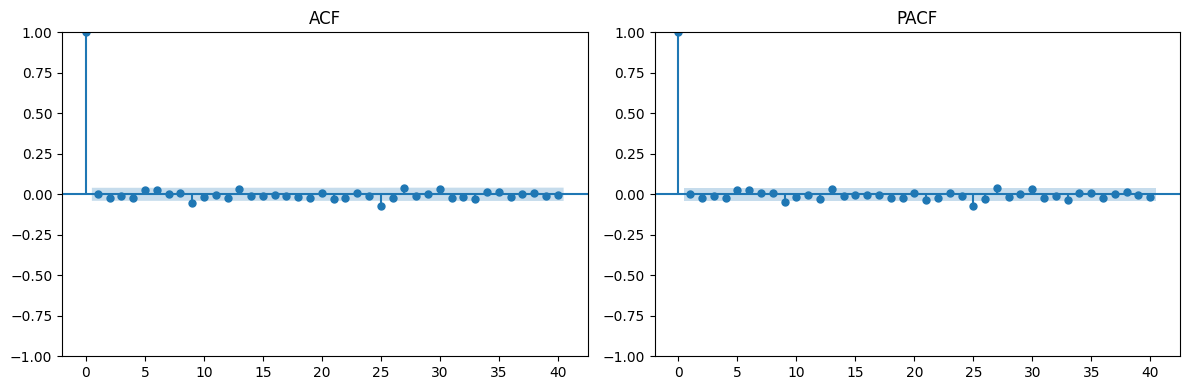

In [397]:
def plot_acf_pacf(series, lags=40):
    series = pd.to_numeric(series, errors='coerce').dropna()
    if isinstance(series, pd.DataFrame):
        raise ValueError("Pass a 1-D Series, not a DataFrame.")
    lags = min(lags, len(series)-2)
    if lags < 1:
        raise ValueError("Not enough data for ACF/PACF.")
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plot_acf(series, lags=lags, ax=plt.gca())
    plt.title("ACF")
    plt.subplot(1,2,2)
    plot_pacf(series, lags=lags, ax=plt.gca(), method="ywm")
    plt.title("PACF")
    plt.tight_layout()
    plt.show()

# Use returns (stationary) instead of raw prices:
stock = get_stock_data("VZ UN", "2010", "2019")
returns = np.log(stock).diff().dropna()   # or stock.pct_change().dropna()
plot_acf_pacf(returns)
